# L'illusion flash-son : résultats

Réplication en ligne de **Shams, Kamitani & Shimojo (2000), *What you see is what you hear*, Nature 408:788** ([doi:10.1038/35048669](https://doi.org/10.1038/35048669)), avec la variante « fusion » d'**Andersen, Tiippana & Sams (2004)** ([doi:10.1016/j.cogbrainres.2004.06.004](https://doi.org/10.1016/j.cogbrainres.2004.06.004)).

**La question.** Le son peut-il changer ce que l'on *voit* ? Le participant voit 1 ou 2 flashs très brefs, accompagnés de 0, 1 ou 2 bips, et dit combien de **flashs** il a vus en ignorant les bips.

## Résumé

- **24 sessions reçues, 6 exclues** selon des critères fixés avant la collecte, **18 participants analysés** (18–25 ans).
- **Fission (H1, confirmée).** Avec 1 flash et 2 bips, les participants voient 2 flashs dans **54 %** des essais, contre **3 %** avec le flash seul (+51 points, p < 0,001, effet très fort : d = 1,8). 13 participants sur 18 sont trompés au moins une fois sur deux.
- **Fusion (H2, confirmée).** Un seul bip fait « disparaître » le 2e flash : 2 flashs vus comme 1 dans **89 %** des essais contre **72 %** sans son (+17 points, p = 0,002).
- **La fission est plus forte que la fusion (H3, confirmée)** : +34 points d'écart (p < 0,001).
- **Interaction flashs × bips (H4)** : présente mais faible (p = 0,047), et due surtout au fait qu'un seul bip ne peut rien retirer quand il n'y a qu'un flash.
- **Fenêtre temporelle (H5, confirmée).** Si les 2 bips sont séparés de 200 ms au lieu de 57 ms, l'illusion disparaît presque : 12 % de « 2 flashs » au lieu de 54 % (p < 0,001).
- **Au-delà des articles** (analyses exploratoires) :
  1. sans son, **2 vrais flashs à 50 ms d'écart ne sont vus comme 2 que dans 28 % des essais** ; avec 2 bips, dans **78 %**. Le son ne fait pas que tromper : il aide aussi à voir un vrai double flash ;
  2. en cas de conflit entre l'image et le son, la réponse suit **le son dans 71 % des cas** (17 participants sur 18) ;
  3. d'après la théorie de la détection du signal, les bips ne changent pas la capacité à distinguer 1 et 2 flashs, ils **déplacent tout vers « 2 »** ;
  4. ceux qui voient le mieux 2 flashs sans son semblent un peu **moins trompés** (corrélation −0,47, p = 0,048, à confirmer) ;
  5. les réponses illusoires sont **plus lentes** (≈ 270 ms) que les réponses à un vrai double flash : on hésite plus ;
  6. pas de différence nette selon l'âge ou le type de son, et une légère baisse de l'illusion en fin de session, non significative.

**En une phrase :** quand l'œil et l'oreille ne sont pas d'accord sur le nombre d'événements rapides, le cerveau fait surtout confiance à l'oreille, mais seulement si les sons tombent dans une courte fenêtre de temps autour du flash.

## Le plan de l'expérience

58 essais principaux par personne, dans un ordre aléatoire (≈ 4 min), après un test d'écoute (3 essais) et un entraînement (3 essais) :

| Partie | Conditions (F = flash, B = bip) | Essais |
|---|---|---|
| Cœur 2 × 3 | 1 ou 2 flashs × 0, 1 ou 2 bips (bips à 57 ms d'écart, flashs à 50 ms) | 6 × 8 = 48 |
| Écart | 1 flash + 2 bips séparés de **200 ms** (`1F2B_gap200`) | 6 |
| Contrôle d'attention | 2 flashs bien séparés (150 ms), sans son (`2F0B_catch`) | 4 |

**Hypothèses fixées avant la collecte** (voir [docs/PLAN.md](../docs/PLAN.md)) : **H1** fission (1F2B vu « 2 » plus souvent que 1F0B) ; **H2** fusion (2F1B vu « 1 » plus souvent que 2F0B) ; **H3** fission plus forte que fusion ; **H4** interaction flashs × bips ; **H5** moins de fission quand les bips sont séparés de 200 ms.

**Méthode statistique** (simple et robuste) : on calcule d'abord un pourcentage **par participant**, puis on compare les conditions chez les mêmes personnes avec un **t de Student apparié** (unilatéral pour H1, H2, H3 et H5, car la direction était prédite), vérifié par un **test de Wilcoxon** (qui ne suppose pas de loi normale). On donne aussi la taille d'effet (**d de Cohen**) et un **intervalle de confiance à 95 % par bootstrap**. H4 est testée par une ANOVA à mesures répétées 2 × 3.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

# chemins relatifs : le notebook marche depuis la racine du dépôt ou depuis analysis/
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data" / "processed" / "trials_anon.csv"
FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Les données

Chaque session envoie automatiquement un fichier CSV (une ligne par essai). Les fichiers bruts restent privés (`data/raw/`, ignoré par git). Le script `scripts/anonymize_data.py` en tire **`data/processed/trials_anon.csv`**, publié dans le dépôt : sans code de session, ni date et heure, ni navigateur détaillé, ni taille d'écran ; les participants sont renommés P01 à P24 dans un ordre qui ne suit pas l'ordre de passage. Le fichier de test du développeur (données simulées) n'en fait pas partie.

In [2]:
df = pd.read_csv(DATA)
print(f"{df.participant.nunique()} sessions reçues, {len(df)} lignes (une ligne = un essai)")

24 sessions reçues, 1545 lignes (une ligne = un essai)


## 2. Qui est gardé ? (critères d'exclusion)

Les critères ont été fixés **avant** de regarder les résultats ([docs/DONNEES.md](../docs/DONNEES.md)).

- **Essai retiré** : image perdue pendant le stimulus, flash en retard de plus d'une demi-image, son programmé trop tard, onglet masqué, ou réponse en moins de 100 ms (touche pressée trop tôt) ou en plus de 10 s.
- **Session exclue** : écouteurs Bluetooth (son retardé), test d'écoute raté (< 2/3), contrôles ratés (< 75 % de « 2 » pour 2 flashs bien séparés, < 70 % de « 1 » pour 1 flash seul), écran < 50 Hz (le flash et l'écart de 50 ms ne peuvent pas être affichés correctement), plus de 20 % d'essais au timing raté, moins de 80 % des essais faits.

In [3]:
def last_score(s):
    """'3/3' ou '1/3;2/3' (test d'écoute refait) -> proportion correcte à la dernière tentative."""
    a, b = str(s).split(";")[-1].split("/")
    return int(a) / int(b)

main = df[df.block == "main"].copy()
main["two"] = (main.response == 2).astype(int)      # 1 si la personne a répondu « 2 flashs »

# Critères d'essai (fixés avant la collecte, docs/DONNEES.md)
main["bad_timing"] = ((main.n_dropped_frames.fillna(0) > 0)
                      | (main.flash_late_ms.abs() > main.frame_ms / 2).fillna(False)
                      | (main.audio_scheduled_late.fillna(0) == 1)
                      | (main.tab_hidden.fillna(0) == 1))
main["bad_rt"] = (main.rt_ms < 100) | (main.rt_ms > 10000)
main["exclude_trial"] = main.bad_timing | main.bad_rt

g = main.groupby("participant")
q = pd.DataFrame({
    "age": g.age_bracket.first(), "son": g.audio_device.first(), "navigateur": g.browser.first(),
    "ecran_hz": g.refresh_hz.median().round(1),
    "test_ecoute": g.audio_check_score.first().map(last_score).round(2),
    "controle_2flashs": main[main.condition == "2F0B_catch"].groupby("participant").two.mean(),
    "controle_1flash": 1 - main[main.condition == "1F0B"].groupby("participant").two.mean(),
    "essais_timing_rate": g.bad_timing.mean().round(2),
    "n_essais": g.size(),
})
n_expected = (pd.read_csv(ROOT / "experiment" / "trials.csv").block == "main").sum()

raisons = pd.DataFrame({
    "Bluetooth": q.son == "bluetooth",
    "test d'écoute < 2/3": q.test_ecoute < 2 / 3 - 1e-9,
    "contrôle 2 flashs < 75 %": q.controle_2flashs < 0.75,
    "contrôle 1 flash < 70 %": q.controle_1flash < 0.70,
    "écran < 50 Hz": q.ecran_hz < 50,
    "timing raté > 20 % des essais": q.essais_timing_rate > 0.20,
    "incomplet": q.n_essais < 0.8 * n_expected,
})
q["exclu"] = raisons.any(axis=1)
q["raison"] = raisons.apply(lambda r: " ; ".join(r.index[r]), axis=1)
display(q)

kept = q.index[~q.exclu]
N_RECUS, N_EXCLUS, N = len(q), int(q.exclu.sum()), len(kept)
print(f"Sessions reçues : {N_RECUS} | exclues : {N_EXCLUS} | ANALYSÉES : N = {N}")
print("\nRaisons d'exclusion (une session peut en cumuler plusieurs) :")
print(raisons.sum()[raisons.sum() > 0].to_string())
d = main[main.participant.isin(kept) & ~main.exclude_trial].copy()
print(f"\nEssais retirés chez les {N} participants gardés : "
      f"{main[main.participant.isin(kept)].exclude_trial.mean():.1%}")

,age,son,navigateur,ecran_hz,test_ecoute,controle_2flashs,controle_1flash,essais_timing_rate,n_essais,exclu,raison
participant,,,,,,,,,,,
P01,22-25,speakers,Edge,59.9,1.00,0.75,1.000,0.00,58,False,
P02,18-21,speakers,Chrome,60.2,1.00,1.00,1.000,0.02,58,False,
P03,18-21,speakers,Chrome,48.1,0.33,0.75,0.875,0.00,58,True,test d'écoute < 2/3 ; écran < 50 Hz
P04,18-21,speakers,Chrome,59.9,1.00,1.00,1.000,0.00,58,False,
P05,22-25,wired,Firefox,60.0,1.00,1.00,1.000,0.00,58,False,
P06,18-21,speakers,Safari,58.8,1.00,1.00,1.000,0.00,58,False,
P07,22-25,speakers,Chrome,59.9,1.00,1.00,0.875,0.02,58,False,
P08,18-21,speakers,Firefox,60.0,1.00,1.00,0.875,0.02,58,False,
P09,22-25,bluetooth,Safari,30.3,1.00,1.00,1.000,0.00,58,True,Bluetooth ; écran < 50 Hz


Sessions reçues : 24 | exclues : 6 | ANALYSÉES : N = 18

Raisons d'exclusion (une session peut en cumuler plusieurs) :
Bluetooth                        1
test d'écoute < 2/3              1
contrôle 2 flashs < 75 %         1
écran < 50 Hz                    3
timing raté > 20 % des essais    2

Essais retirés chez les 18 participants gardés : 2.7%


**Bilan : 24 sessions reçues, 6 exclues, N = 18 participants analysés.** Les 6 exclusions : 3 écrans à moins de 50 Hz (dont une session aussi en Bluetooth et une aussi au test d'écoute raté), 2 sessions avec trop d'images perdues, 1 session ratant le contrôle d'attention. Chez les 18 participants gardés, seuls 2,7 % des essais sont retirés. La section 8 refait les tests principaux avec les 24 sessions, pour vérifier que les exclusions ne changent pas les conclusions.

In [4]:
print("Participants analysés :")
print(q.loc[kept].age.value_counts().sort_index().rename("tranche d'âge").to_string(), "\n")
print(q.loc[kept].son.value_counts().rename("type de son").to_string(), "\n")
print(q.loc[kept].navigateur.value_counts().rename("navigateur").to_string())

Participants analysés :
age
18-21     8
22-25    10 

son
speakers    14
wired        4 

navigateur
Firefox    8
Chrome     6
Edge       3
Safari     1


## 3. Ce que les participants ont vu

Pour chaque participant et chaque condition, on calcule le **nombre moyen de flashs rapportés** (comme la figure 1 de Shams et al., 2000), puis la moyenne du groupe.

In [5]:
ORDER = ["1F0B", "1F1B", "1F2B", "2F0B", "2F1B", "2F2B"]
core = d[d.part == "core"]
# proportion de réponses « 2 flashs » par participant et par condition
P = d.pivot_table(index="participant", columns="condition", values="two", aggfunc="mean")
nflash = core.pivot_table(index="participant", columns="condition", values="response", aggfunc="mean")[ORDER]
print("Nombre moyen de flashs perçus (moyenne des participants ± écart-type) :")
display(nflash.agg(["mean", "std"]).round(2))
print("Pourcentage de réponses « 2 flashs » :")
display((100 * P[ORDER + ["1F2B_gap200", "2F0B_catch"]].agg(["mean", "std"])).round(0))

Nombre moyen de flashs perçus (moyenne des participants ± écart-type) :


condition,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
mean,1.03,1.03,1.54,1.28,1.11,1.78
std,0.09,0.07,0.29,0.30,0.21,0.23


Pourcentage de réponses « 2 flashs » :


condition,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B,1F2B_gap200,2F0B_catch
mean,3.0,3.0,54.0,28.0,11.0,78.0,12.0,99.0
std,9.0,7.0,29.0,30.0,21.0,23.0,29.0,6.0


**Lecture.** Les bips tirent la réponse vers leur propre nombre : 1 flash + 2 bips est vu en moyenne comme **1,54** flash (contre 1,03 sans son). Le contrôle à 150 ms est réussi à 99 %, donc les participants étaient attentifs. Point inattendu : **2 flashs à 50 ms d'écart sans son ne sont vus comme 2 que dans 28 % des essais**. Sur un écran d'ordinateur ordinaire, deux flashs aussi rapprochés se confondent souvent. On y revient en section 7.

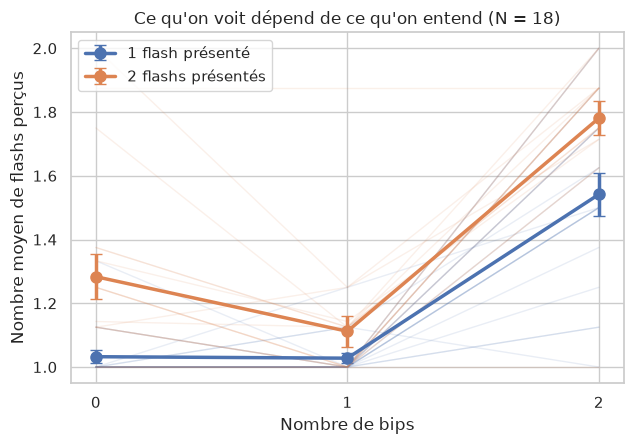

In [6]:
long = nflash.reset_index().melt(id_vars="participant", var_name="cond", value_name="flashs")
long["n_flashes"] = long.cond.str[0].astype(int)
long["n_beeps"] = long.cond.str[2].astype(int)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for nf, col in [(1, "C0"), (2, "C1")]:
    sub = long[long.n_flashes == nf]
    for pid, gp in sub.groupby("participant"):
        ax.plot(gp.n_beeps, gp.flashs, color=col, alpha=0.12, lw=1)
    m_ = sub.groupby("n_beeps").flashs.agg(["mean", "sem"])
    ax.errorbar(m_.index, m_["mean"], yerr=m_["sem"], marker="o", ms=8, lw=2.5, capsize=4, color=col,
                label="1 flash présenté" if nf == 1 else "2 flashs présentés")
ax.set_xticks([0, 1, 2]); ax.set_ylim(0.95, 2.05)
ax.set_xlabel("Nombre de bips"); ax.set_ylabel("Nombre moyen de flashs perçus")
ax.set_title(f"Ce qu'on voit dépend de ce qu'on entend (N = {N})")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_flashs_percus.png", dpi=150); plt.show()

## 4. Les hypothèses H1, H2, H3 et H5

Indices par participant : **fission** = % de « 2 » pour 1F2B − % de « 2 » pour 1F0B ; **fusion** = % de « 1 » pour 2F1B − % de « 1 » pour 2F0B. Les différences sont des proportions : 0,51 = 51 points de pourcentage.

In [7]:
def boot_ci(x, n=10000):
    """Intervalle de confiance à 95 % de la moyenne par bootstrap (rééchantillonnage des participants)."""
    x = np.asarray(x, float)
    rng = np.random.default_rng(2026)   # graine fixe : résultat reproductible
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

def compare(a, b, label, alternative="greater"):
    """a vs b, mêmes participants : t apparié, Wilcoxon, d de Cohen (dz) et IC bootstrap de la différence."""
    diff = (np.asarray(a, float) - np.asarray(b, float))
    t = stats.ttest_rel(a, b, alternative=alternative)
    try:
        w = stats.wilcoxon(a, b, alternative=alternative).pvalue
    except ValueError:
        w = np.nan
    lo, hi = boot_ci(diff)
    return pd.Series({"différence moyenne": diff.mean(), "IC95 bas": lo, "IC95 haut": hi,
                      "t": t.statistic, "ddl": len(diff) - 1, "p (t)": t.pvalue,
                      "p (Wilcoxon)": w, "d de Cohen (dz)": diff.mean() / diff.std(ddof=1)}, name=label)

def fmt(tab):
    out = tab.copy()
    for c in out.columns:
        if c.startswith("p "):
            out[c] = out[c].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
        elif c == "ddl":
            out[c] = out[c].astype(int)
        else:
            out[c] = out[c].astype(float).round(2)
    return out

idx = pd.DataFrame({
    "fission": P["1F2B"] - P["1F0B"],            # « 2 » de plus quand 2 bips accompagnent 1 flash
    "fusion": (1 - P["2F1B"]) - (1 - P["2F0B"]), # « 1 » de plus quand 1 bip accompagne 2 flashs
    "fission_200ms": P["1F2B_gap200"] - P["1F0B"],
})
res = pd.DataFrame([
    compare(P["1F2B"], P["1F0B"], "H1 fission : 1F2B vs 1F0B (% « 2 »)"),
    compare(1 - P["2F1B"], 1 - P["2F0B"], "H2 fusion : 2F1B vs 2F0B (% « 1 »)"),
    compare(idx.fission, idx.fusion, "H3 fission > fusion (indices)"),
    compare(P["1F2B"], P["1F2B_gap200"], "H5 bips à 57 ms vs 200 ms (% « 2 »)"),
])
display(fmt(res))

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
H1 fission : 1F2B vs 1F0B (% « 2 »),0.51,0.38,0.63,7.67,17,"< 0,001","< 0,001",1.81
H2 fusion : 2F1B vs 2F0B (% « 1 »),0.17,0.08,0.28,3.28,17,0.002,0.002,0.77
H3 fission > fusion (indices),0.34,0.17,0.51,3.82,17,"< 0,001",0.002,0.90
H5 bips à 57 ms vs 200 ms (% « 2 »),0.42,0.27,0.57,5.35,17,"< 0,001","< 0,001",1.26


**Résultats.**
- **H1 (fission) confirmée** : +51 points (IC 95 % : 38 à 63), t(17) = 7,67, p < 0,001, d = 1,81.
- **H2 (fusion) confirmée** : +17 points (IC 95 % : 8 à 28), t(17) = 3,28, p = 0,002, d = 0,77. Shams et al. (2000) ne trouvaient pas de fusion nette ; nous la trouvons, comme Andersen et al. (2004), mais plus faible que la fission.
- **H3 (fission > fusion) confirmée** : écart de 34 points (IC 95 % : 17 à 51), t(17) = 3,82, p < 0,001, d = 0,90.
- **H5 (fenêtre temporelle) confirmée** : avec des bips à 200 ms d'écart, la fission tombe de 54 % à 12 % de « 2 » (−42 points, IC 95 % : 27 à 57, t(17) = 5,35, p < 0,001, d = 1,26). Le cerveau ne lie le son au flash que s'ils sont très proches dans le temps.

Le test de Wilcoxon donne les mêmes conclusions à chaque fois.

## 5. H4 : interaction flashs × bips (ANOVA à mesures répétées)

Variable : % de réponses « 2 » ; facteurs : nombre de flashs (1, 2) et nombre de bips (0, 1, 2). La colonne `p_GG_corr` corrige la violation de sphéricité (Greenhouse-Geisser).

In [8]:
aov = pg.rm_anova(data=core.groupby(["participant", "n_flashes", "n_beeps"], as_index=False).two.mean(),
                  dv="two", within=["n_flashes", "n_beeps"], subject="participant", correction=True)
display(aov.round(4))

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps,sphericity,W_spher,p_spher
0,n_flashes,0.9898,1,17,0.9898,12.7296,0.0024,0.0024,0.1707,1.0000,True,NaN,1.0000
1,n_beeps,7.3279,2,34,3.6639,70.9384,0.0000,0.0000,0.6037,0.6362,False,0.4282,0.0011
2,n_flashes * n_beeps,0.1556,2,34,0.0778,3.4366,0.0437,0.0470,0.0313,0.9429,True,0.9395,0.6068


**Résultats.** Le nombre de **bips** a un effet énorme (F(2, 34) = 70,9, p < 0,001, η²g = 0,60), bien plus grand que celui du nombre réel de **flashs** (F(1, 17) = 12,7, p = 0,002, η²g = 0,17). **H4** : l'interaction est significative mais faible (F(2, 34) = 3,44, p = 0,047 après correction, η²g = 0,03). Elle vient du bip unique : il fait baisser les « 2 » quand il y a 2 flashs (fusion), mais ne peut rien faire quand il n'y a qu'un flash, car les « 2 » y sont déjà presque à zéro. Avec 2 bips, la hausse est la même pour 1 et pour 2 flashs (+51 et +50 points). H4 est donc confirmée de justesse, et pour une raison assez simple.

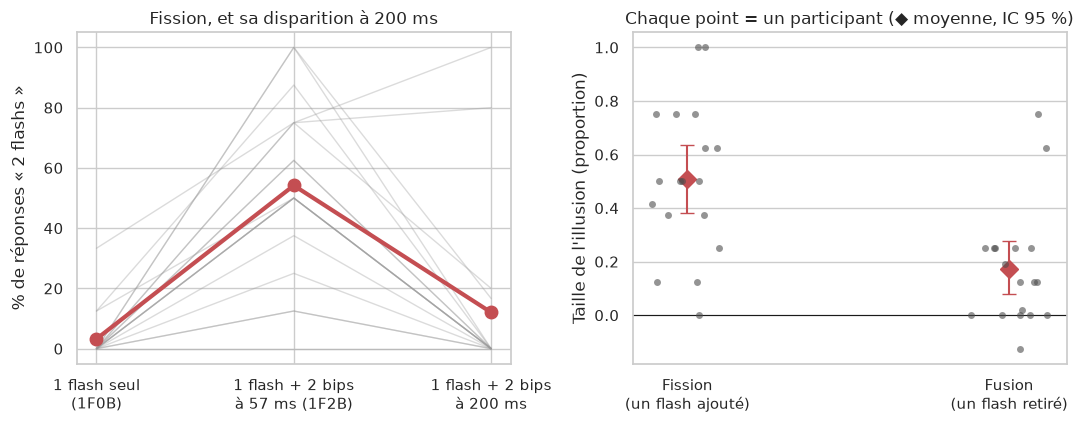

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
plot = pd.DataFrame({"1 flash seul\n(1F0B)": P["1F0B"], "1 flash + 2 bips\nà 57 ms (1F2B)": P["1F2B"],
                     "1 flash + 2 bips\nà 200 ms": P["1F2B_gap200"]}) * 100
for pid, row in plot.iterrows():
    ax.plot(range(3), row.values, color="0.6", alpha=0.35, lw=1)
ax.plot(range(3), plot.mean().values, "o-", color="C3", lw=3, ms=9)
ax.set_xticks(range(3)); ax.set_xticklabels(plot.columns)
ax.set_ylabel("% de réponses « 2 flashs »"); ax.set_ylim(-5, 105)
ax.set_title("Fission, et sa disparition à 200 ms")

ax = axes[1]
sns.stripplot(data=idx[["fission", "fusion"]].melt(), x="variable", y="value", ax=ax, color="0.3",
              alpha=0.6, jitter=0.12)
cis = [boot_ci(idx[c]) for c in ("fission", "fusion")]
means = idx[["fission", "fusion"]].mean().values
ax.errorbar([0, 1], means, fmt="D", color="C3", ms=9, capsize=5,
            yerr=[[m_ - ci[0] for m_, ci in zip(means, cis)], [ci[1] - m_ for m_, ci in zip(means, cis)]])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Fission\n(un flash ajouté)", "Fusion\n(un flash retiré)"])
ax.set_xlabel(""); ax.set_ylabel("Taille de l'illusion (proportion)")
ax.set_title("Chaque point = un participant (◆ moyenne, IC 95 %)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_fission_fusion_ecart.png", dpi=150); plt.show()

## 6. Le son change-t-il la vue, ou seulement la réponse ? (détection du signal)

On considère « 2 flashs » comme le signal à détecter. Le **d′** mesure la capacité à distinguer 1 et 2 flashs ; le **critère c** mesure la tendance à répondre « 2 » (c > 0 : on répond plutôt « 1 » ; c < 0 : plutôt « 2 »). On compare sans son (1F0B vs 2F0B) et avec 2 bips (1F2B vs 2F2B), avec la correction de Hautus (1995) pour les 0 % et 100 %.

In [10]:
def sdt(hit, fa, n_signal, n_noise):
    """d′ et critère c, avec correction log-linéaire (Hautus, 1995) pour éviter les 0 et 100 %."""
    H = (hit * n_signal + 0.5) / (n_signal + 1)
    F = (fa * n_noise + 0.5) / (n_noise + 1)
    return stats.norm.ppf(H) - stats.norm.ppf(F), -0.5 * (stats.norm.ppf(H) + stats.norm.ppf(F))

cnt = core.pivot_table(index="participant", columns="condition", values="two", aggfunc="size")
rows = {}
for lab, s, n_ in [("sans son", "2F0B", "1F0B"), ("2 bips", "2F2B", "1F2B")]:
    dp, c = sdt(P[s], P[n_], cnt[s], cnt[n_])
    rows[f"d′ {lab}"], rows[f"c {lab}"] = dp, c
sd = pd.DataFrame(rows)
display(sd.agg(["mean", "std"]).round(2))
display(fmt(pd.DataFrame([
    compare(sd["d′ sans son"], sd["d′ 2 bips"], "d′ : sans son vs 2 bips", "two-sided"),
    compare(sd["c sans son"], sd["c 2 bips"], "critère c : sans son vs 2 bips", "two-sided")])))

,d′ sans son,c sans son,d′ 2 bips,c 2 bips
mean,0.86,1.02,0.63,-0.42
std,0.95,0.47,1.00,0.58


,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
d′ : sans son vs 2 bips,0.23,-0.22,0.71,0.94,17,0.358,0.381,0.22
critère c : sans son vs 2 bips,1.44,1.09,1.78,7.88,17,"< 0,001","< 0,001",1.86


**Résultats.** La capacité à distinguer 1 et 2 flashs ne change pas (d′ = 0,86 sans son, 0,63 avec 2 bips, p = 0,36), mais le critère bascule fortement vers « 2 » (c = 1,02 → −0,42, p < 0,001, d = 1,86). Les bips ne rendent pas la vision plus fine : ils déplacent l'ensemble des réponses vers « 2 ». Attention : ce modèle ne permet pas à lui seul de dire si ce déplacement se fait dans la perception ou dans la décision.

## 7. Analyses exploratoires : au-delà des articles

Ces analyses n'étaient pas prévues à l'avance. Avec 18 participants, ce sont des **pistes**, sans correction pour les comparaisons multiples.

### 7.1 Le son aide aussi à voir un vrai double flash, et c'est lui qui « gagne »

In [11]:
# Avec 2 bips, les VRAIS doubles flashs sont-ils mieux vus ?
display(fmt(pd.DataFrame([compare(P["2F2B"], P["2F0B"], "2 vrais flashs : avec 2 bips vs sans son", "two-sided")])))

# Quand image et son se contredisent, qui l'emporte ?
conflict = d[d.condition.isin(["1F2B", "2F1B"])].copy()
conflict["suit_son"] = (conflict.response == conflict.n_beeps).astype(int)
suit = conflict.groupby("participant").suit_son.mean()
print(f"Essais en conflit (1F2B et 2F1B) : la réponse suit le nombre de BIPS dans "
      f"{suit.mean():.0%} des cas en moyenne (IC95 bootstrap {boot_ci(suit)[0]:.0%}–{boot_ci(suit)[1]:.0%}) ; "
      f"{(suit > 0.5).sum()} participants sur {N} suivent le son plus d'une fois sur deux.")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
2 vrais flashs : avec 2 bips vs sans son,0.5,0.33,0.65,6.0,17,"< 0,001","< 0,001",1.41


Essais en conflit (1F2B et 2F1B) : la réponse suit le nombre de BIPS dans 71% des cas en moyenne (IC95 bootstrap 61%–80%) ; 17 participants sur 18 suivent le son plus d'une fois sur deux.


Sans son, 2 vrais flashs à 50 ms d'écart ne sont vus comme 2 que dans 28 % des essais. Avec 2 bips, c'est 78 % : **+50 points** (IC 95 % : 33 à 65, p < 0,001). L'oreille corrige une vue trop lente. Et quand l'image et le son se contredisent (1F2B, 2F1B), la réponse suit **le nombre de bips dans 71 % des cas** (IC 95 % : 61 à 80 %), chez 17 participants sur 18. Pour compter des événements rapides, le cerveau se fie surtout à l'audition, plus précise dans le temps que la vision.

### 7.2 Tout le monde n'est pas trompé de la même façon

Indice de fission : médiane 0.50, min 0.00, max 1.00
Participants qui ont vu 2 flashs sur au moins la moitié des essais 1 flash + 2 bips : 13 / 18
Participants qui n'ont presque jamais été trompés (≤ 1 essai sur 8) : 3 / 18

Corrélation (Spearman) fission / fusion : rho = -0.15, p = 0.546
Corrélation (Spearman) bonne vision des 2 flashs sans son (2F0B) / fission : rho = -0.47, p = 0.048


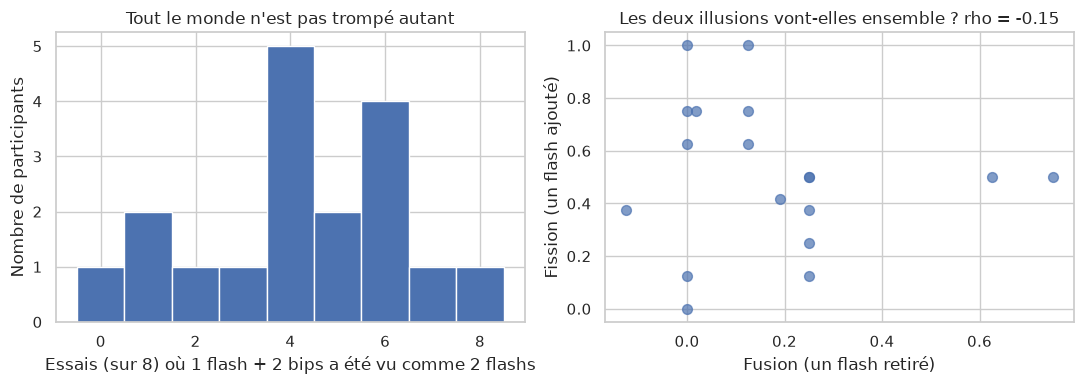

In [12]:
fis = idx.fission
print(f"Indice de fission : médiane {fis.median():.2f}, min {fis.min():.2f}, max {fis.max():.2f}")
print(f"Participants qui ont vu 2 flashs sur au moins la moitié des essais 1 flash + 2 bips : "
      f"{(P['1F2B'] >= 0.5).sum()} / {N}")
print(f"Participants qui n'ont presque jamais été trompés (≤ 1 essai sur 8) : {(P['1F2B'] <= 1/8).sum()} / {N}")

r1 = stats.spearmanr(idx.fission, idx.fusion)
r2 = stats.spearmanr(P["2F0B"], idx.fission)
print(f"\nCorrélation (Spearman) fission / fusion : rho = {r1.statistic:.2f}, p = {r1.pvalue:.3f}")
print(f"Corrélation (Spearman) bonne vision des 2 flashs sans son (2F0B) / fission : "
      f"rho = {r2.statistic:.2f}, p = {r2.pvalue:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
n_illus = d[d.condition == "1F2B"].groupby("participant").two.sum()
axes[0].hist(n_illus, bins=np.arange(-0.5, 9.5, 1), color="C0", edgecolor="w")
axes[0].set_xlabel("Essais (sur 8) où 1 flash + 2 bips a été vu comme 2 flashs")
axes[0].set_ylabel("Nombre de participants"); axes[0].set_title("Tout le monde n'est pas trompé autant")
axes[1].scatter(idx.fusion, idx.fission, s=50, alpha=0.7)
axes[1].set_xlabel("Fusion (un flash retiré)"); axes[1].set_ylabel("Fission (un flash ajouté)")
axes[1].set_title(f"Les deux illusions vont-elles ensemble ? rho = {r1.statistic:.2f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_differences_individuelles.png", dpi=150); plt.show()

**Résultats.** L'illusion varie beaucoup d'une personne à l'autre : 13 participants sur 18 voient 2 flashs au moins une fois sur deux, mais 3 ne sont presque jamais trompés (au plus 1 essai sur 8). Être sensible à la fission ne prédit pas la sensibilité à la fusion (rho = −0,15, p = 0,55) : ce ne sont pas deux faces d'un même « trait ». En revanche, ceux qui voient le mieux 2 flashs sans son semblent **moins trompés** (rho = −0,47, p = 0,048). C'est ce que prédit l'idée que le cerveau donne plus de poids au sens le plus fiable, mais avec 18 personnes et un p tout juste sous 0,05, ce résultat est à confirmer.

### 7.3 L'illusion s'use-t-elle au cours de la session ?

In [13]:
# Effet d'ordre : la fission change-t-elle entre la 1re et la 2e moitié de la session ?
half = d.trial_in_block <= n_expected / 2
f1 = d[half & (d.condition == "1F2B")].groupby("participant").two.mean()
f2 = d[~half & (d.condition == "1F2B")].groupby("participant").two.mean()
both = f1.index.intersection(f2.index)
display(fmt(pd.DataFrame([compare(f2[both], f1[both], "1F2B : 2e moitié vs 1re moitié (% « 2 »)", "two-sided")])))
print(f"(n = {len(both)} participants ayant des essais 1F2B dans les deux moitiés)")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
1F2B : 2e moitié vs 1re moitié (% « 2 »),-0.17,-0.35,0.01,-1.79,17,0.091,0.096,-0.42


(n = 18 participants ayant des essais 1F2B dans les deux moitiés)


La fission baisse de 17 points entre la 1re et la 2e moitié de la session (IC 95 % : −35 à +1, p = 0,09). C'est une tendance, **non significative** : on ne peut pas conclure à un effet d'habitude.

### 7.4 Temps de réponse

Le temps de réponse n'était pas limité, et les consignes ne demandaient pas d'aller vite : ces résultats sont donc indicatifs.

In [14]:
# Temps de réponse : voir un flash « en plus » est-il aussi rapide que voir 2 vrais flashs ?
med = lambda cond, resp: d[(d.condition == cond) & (d.response == resp)].groupby("participant").rt_ms.median()
rt_illus, rt_vrai, rt_non = med("1F2B", 2), med("2F2B", 2), med("1F2B", 1)
both = rt_illus.index.intersection(rt_vrai.index)
both2 = rt_illus.index.intersection(rt_non.index)
display(fmt(pd.DataFrame([
    compare(rt_illus[both], rt_vrai[both], "TR (ms) : « 2 » illusoire (1F2B) vs « 2 » juste (2F2B)", "two-sided"),
    compare(rt_illus[both2], rt_non[both2], "TR (ms) : 1F2B répondu « 2 » vs répondu « 1 »", "two-sided")])))
print(f"n = {len(both)} et {len(both2)} participants. Médianes du groupe : illusoire {rt_illus.median():.0f} ms, "
      f"2 vrais flashs {rt_vrai.median():.0f} ms, 1F2B répondu « 1 » {rt_non.median():.0f} ms")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
TR (ms) : « 2 » illusoire (1F2B) vs « 2 » juste (2F2B),272.56,114.45,449.57,3.03,15,0.008,0.005,0.76
TR (ms) : 1F2B répondu « 2 » vs répondu « 1 »,151.62,-271.89,572.51,0.69,14,0.501,0.359,0.18


n = 16 et 15 participants. Médianes du groupe : illusoire 771 ms, 2 vrais flashs 601 ms, 1F2B répondu « 1 » 738 ms


Répondre « 2 » pour 1 flash + 2 bips (réponse illusoire) prend **≈ 270 ms de plus** que répondre « 2 » pour 2 vrais flashs avec 2 bips (IC 95 % : 114 à 450 ms, p = 0,008, n = 16). Cela suggère que le flash illusoire est moins net qu'un vrai. Dans la condition 1F2B, les réponses « 2 » ne sont pas plus lentes que les réponses « 1 » (p = 0,50, n = 15).

### 7.5 Type de son et âge

Groupes très petits (4 casques filaires contre 14 haut-parleurs ; 8 personnes de 18–21 ans contre 10 de 22–25 ans) : simple description.

In [15]:
# Type de son et âge (petits groupes : descriptif, à prendre avec prudence)
info = q.loc[kept, ["son", "age"]].join(idx)
for col in ["son", "age"]:
    print(info.groupby(col)[["fission", "fusion", "fission_200ms"]].agg(["mean", "count"]).round(2), "\n")
    grp = [gp.fission.values for _, gp in info.groupby(col)]
    if len(grp) == 2:
        u = stats.mannwhitneyu(*grp, alternative="two-sided")
        print(f"Mann-Whitney sur la fission ({col}) : U = {u.statistic:.1f}, p = {u.pvalue:.3f}\n")

         fission       fusion       fission_200ms      
            mean count   mean count          mean count
son                                                    
speakers    0.53    14   0.18    14          0.08    14
wired       0.45     4   0.14     4          0.12     4 

Mann-Whitney sur la fission (son) : U = 34.5, p = 0.520

      fission       fusion       fission_200ms      
         mean count   mean count          mean count
age                                                 
18-21    0.61     8   0.23     8          0.13     8
22-25    0.43    10   0.12    10          0.05    10 

Mann-Whitney sur la fission (age) : U = 55.5, p = 0.179



Aucune différence nette : fission de 0,45 (filaire) contre 0,53 (haut-parleurs), p = 0,52 ; de 0,61 (18–21 ans) contre 0,43 (22–25 ans), p = 0,18. Avec si peu de personnes par groupe, l'absence de différence ne prouve pas qu'il n'y en a pas. Le résultat rassure quand même : les haut-parleurs n'ont pas détruit l'illusion.

## 8. Robustesse : sans aucune exclusion de session

In [16]:
# Robustesse : mêmes tests avec TOUTES les sessions reçues (sans aucune exclusion de session)
dall = main[~main.exclude_trial]
Pa = dall.pivot_table(index="participant", columns="condition", values="two", aggfunc="mean")
display(fmt(pd.DataFrame([
    compare(Pa["1F2B"], Pa["1F0B"], "H1 fission"),
    compare(1 - Pa["2F1B"], 1 - Pa["2F0B"], "H2 fusion"),
    compare(Pa["1F2B"] - Pa["1F0B"], Pa["2F0B"] - Pa["2F1B"], "H3 fission > fusion"),
    compare(Pa["1F2B"], Pa["1F2B_gap200"], "H5 57 vs 200 ms")])))
print(f"N = {len(Pa)} sessions")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
H1 fission,0.51,0.40,0.63,8.50,23,"< 0,001","< 0,001",1.74
H2 fusion,0.12,-0.01,0.24,1.94,23,0.032,0.003,0.40
H3 fission > fusion,0.39,0.21,0.58,4.08,23,"< 0,001","< 0,001",0.83
H5 57 vs 200 ms,0.46,0.32,0.59,6.43,23,"< 0,001","< 0,001",1.31


N = 24 sessions


Avec les 24 sessions, H1, H3 et H5 restent nettes (p < 0,001). La fusion (H2) est plus faible (+12 points, t(23) = 1,94, p = 0,03 ; Wilcoxon p = 0,003 ; l'IC 95 %, de −1 à +24 points, inclut tout juste 0). Les sessions exclues (écrans à 30 Hz notamment) affichaient probablement mal le double flash, ce qui brouille surtout cette illusion, la plus fragile. Les conclusions ne dépendent donc pas des exclusions.

## 9. Qualité du timing (mesurée par le navigateur)

In [17]:
tim = main[main.participant.isin(kept)]
print(f"Écran : {tim.refresh_hz.median():.1f} Hz en médiane ; durée réelle d'un flash : "
      f"{tim.flash_dur_ms_actual.median():.1f} ms ; écart réel entre 2 flashs : {tim[tim.part=='core'].flash_soa_ms_actual.median():.1f} ms")
print(f"Images perdues : {(tim.n_dropped_frames > 0).mean():.1%} des essais ; "
      f"décalage son-image estimé par le navigateur : médiane {tim.av_offset_est_ms.abs().median():.2f} ms, "
      f"max {tim.av_offset_est_ms.abs().max():.1f} ms")
print(f"Latence de sortie audio annoncée : médiane {tim.output_latency_ms.median():.0f} ms "
      f"(compensée par le programme : outputTimestamp)")

Écran : 60.0 Hz en médiane ; durée réelle d'un flash : 16.7 ms ; écart réel entre 2 flashs : 50.0 ms
Images perdues : 1.5% des essais ; décalage son-image estimé par le navigateur : médiane 0.40 ms, max 6.0 ms
Latence de sortie audio annoncée : médiane 39 ms (compensée par le programme : outputTimestamp)


Le navigateur ne peut mesurer ni l'instant où la lumière sort de l'écran, ni celui où le son sort du casque. Mais ce qu'il peut mesurer est bon : flash d'une image à 60 Hz (16,7 ms), écart de 50 ms respecté, peu d'images perdues, son programmé au bon moment.

## 10. Conclusion

Avec **18 participants** testés en ligne sur leur propre ordinateur, on retrouve l'illusion de Shams et al. (2000) avec un effet très fort : **un flash accompagné de deux bips est vu comme deux flashs dans plus de la moitié des essais**. On retrouve aussi l'illusion inverse (fusion), plus faible, et on montre que tout dépend du **timing** : à 200 ms d'écart entre les bips, l'illusion disparaît presque.

Ce que ces données ajoutent : le son ne fait pas que tromper, il **aide aussi** à voir un vrai double flash trop rapide pour l'œil ; il « gagne » dans 71 % des conflits ; et les personnes qui voient bien sans son semblent moins trompées. Tout cela va dans le même sens : **pour compter des événements rapides, le cerveau fait surtout confiance au sens le plus précis dans le temps, l'audition.**

**Limites.**
- Petit échantillon de convenance (18 personnes de 18 à 25 ans).
- Peu d'essais par condition (6 à 8), donc des scores individuels bruités.
- Son et image non mesurés physiquement ; matériel différent d'une personne à l'autre ; surtout des haut-parleurs.
- Réponses limitées à 1 ou 2 flashs (Shams et al. allaient jusqu'à 4).
- Une même personne a pu faire l'expérience deux fois, car les données sont anonymes.
- Les analyses de la section 7 sont exploratoires et demandent à être confirmées.

**Références.** Shams, Kamitani & Shimojo (2000), *Nature* 408:788 · Shams, Kamitani & Shimojo (2002), *Cognitive Brain Research* 14:147 · Andersen, Tiippana & Sams (2004), *Cognitive Brain Research* 21:301 · Hautus (1995), *Behavior Research Methods* 27:46.